# 02 · Machine learning: ¿cuántos cajeros le corresponden a cada zona?

**TPO Ciencia de Datos · ¿Dónde faltan cajeros Link en CABA?**

En la clase 2 vimos cuatro niveles de análisis. Este notebook cubre el **predictivo** y el **diagnóstico** que lo explica:

| Nivel | Pregunta | Dónde |
|---|---|---|
| Descriptivo | ¿Dónde están los cajeros y dónde está la gente? | notebook 01 |
| Diagnóstico | ¿Qué hace que una zona tenga más cajeros? | este notebook (§4 y §6) |
| **Predictivo** | ¿Cuántos cajeros le corresponden a cada zona? ¿Cuánta gente va a viajar? | este notebook y el 05 |
| Prescriptivo | ¿Dónde conviene poner los próximos cajeros? | notebook 03 |

Dos preguntas de negocio, dos modelos supervisados:

| Pregunta | Tipo | Objetivo (y) | Modelos comparados |
|---|---|---|---|
| ¿Cuántas terminales le corresponden a cada zona según su demanda? | Regresión | terminales en el área de influencia | regresión de Poisson, árbol de decisión (clase 6), Random Forest y XGBoost (clase 8), ensamble |
| ¿A esta zona le corresponde al menos un cajero? | Clasificación | la zona tiene o no un cajero | regresión logística, árbol de decisión, Random Forest, XGBoost |

Todo se evalúa con **validación cruzada espacial anidada**: el modelo siempre se mide en comunas que no vio.

In [1]:
import json, sys, time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src import estilo as e, features as f, graficos_ml as gm, ml, modelos as m

e.mpl_estilo()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = RAIZ / "docs/figuras"; FIG.mkdir(parents=True, exist_ok=True)
PROC = RAIZ / "data/processed"

# True: entrena y valida todos los modelos acá mismo (unos 6 minutos con 2 núcleos).
# False: muestra lo que ya calculó el pipeline (python -m src.pipeline), en segundos.
# Da lo mismo: todo usa semilla fija, así que los números coinciden.
RECALCULAR = True

tabla = pd.read_parquet(PROC / "hexagonos.parquet")      # variables por hexágono (src/features.py)
res = pd.read_parquet(PROC / "resultados_hex.parquet")   # + predicciones fuera de muestra del pipeline
barrios = f.cargar_barrios()
X, y, grupos, mascara = m.preparar(tabla)
print(f"{e.num_es(len(X))} hexágonos para modelar · {X.shape[1]} variables · objetivo: terminales en el área de influencia")

2.740 hexágonos para modelar · 14 variables · objetivo: terminales en el área de influencia


## 1. Planteo

- **Unidad:** hexágono H3 de resolución 9 (unas 3 × 3 manzanas). Variables y objetivo se miden en su **área de influencia**:
  el hexágono y sus 6 vecinos, unos 400 m, la escala de una caminata.
- **Objetivo (regresión):** terminales de cajero de cualquier red en el área. Es un **conteo** con muchos ceros y cola larga,
  así que usamos pérdida de Poisson y medimos con la **devianza de Poisson (D²)**, el equivalente del R² para conteos.
  También reportamos el **error absoluto medio (MAE)**: cuántas terminales erra, en promedio, por zona.
- **Variables:** solo de **demanda**: residentes, perfil socioeconómico (censo), comercio y oficinas (usos del suelo y
  OpenStreetMap), pasajeros de subte (molinetes) y distancias. Dejamos afuera sucursales y cajeros: son oferta, y el
  modelo terminaría explicando cajeros con cajeros.

In [2]:
pd.DataFrame({"variable": X.columns, "descripción": [ml.NOMBRES.get(c, c) for c in X.columns],
              "mediana": X.median().values, "máximo": X.max().values})

,variable,descripción,mediana,máximo
0,poblacion_k1,Residentes en el área,"6,844.790","29,551.160"
1,actividad_osm_k1,Comercios y servicios (OSM),41.000,835.000
2,pax_subte_habil_k1,Pasajeros de subte por día hábil,0.000,"54,272.000"
3,estaciones_tren_k1,Estaciones de tren,0.000,3.000
4,dist_centro_km,Distancia a Plaza de Mayo (km),8.807,15.316
5,dist_subte_m,Distancia al subte (m),"1,399.702","6,653.628"
6,pct_nbi_k1,% hogares con NBI,0.035,0.330
7,pct_sin_internet_k1,% hogares sin internet,0.099,0.583
8,pct_65_k1,% de 65 años o más,0.175,0.284
9,pct_univ_k1,% con nivel universitario,0.173,0.415


### Cómo separamos entrenamiento y prueba

Las zonas vecinas se parecen y comparten área de influencia. Si mezclamos al azar entrenamiento y prueba, el modelo "ve" la
respuesta en los vecinos y el error parece menor de lo que es. Por eso hacemos **validación cruzada espacial**: armamos
5 grupos de comunas (GroupKFold) y, por turno, entrenamos con 4 y medimos en el quinto.

Además es **anidada**: los hiperparámetros (profundidad de los árboles, cantidad de hojas, regularización) se eligen con
GridSearchCV **adentro** de las 4 partes de entrenamiento, también dejando comunas afuera. Así el grupo de prueba nunca
participa de ninguna decisión del modelo.

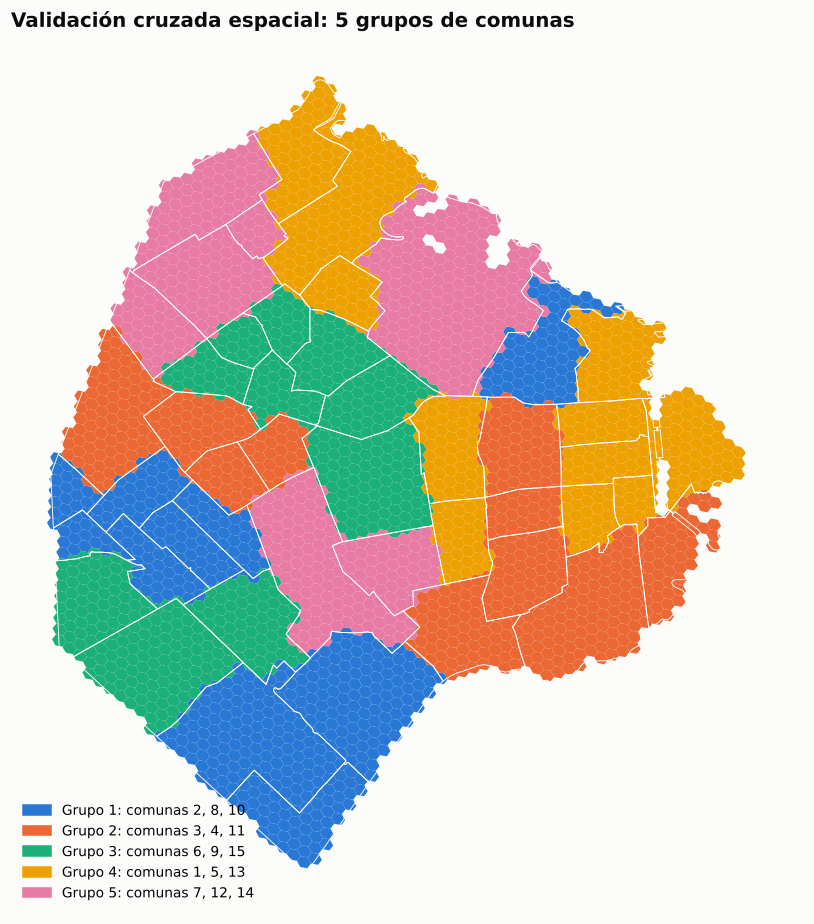

In [3]:
particion = pd.Series(0, index=X.index)
for k, (_, te) in enumerate(GroupKFold(n_splits=ml.PLIEGUES).split(X, y, grupos), start=1):
    particion.iloc[te] = k
g = gpd.GeoDataFrame({"particion": particion.values}, geometry=[f.poligono_hex(h) for h in tabla.loc[mascara, "h3"]], crs="EPSG:4326")
fig, ax = plt.subplots(figsize=(9, 8.5))
for k in range(1, ml.PLIEGUES + 1):
    comunas = sorted(grupos[particion == k].unique())
    g[g["particion"] == k].plot(ax=ax, color=e.CATEGORICO[k - 1], linewidth=0, label=f"Grupo {k}: comunas {', '.join(map(str, comunas))}")
barrios.boundary.plot(ax=ax, color=e.FONDO, linewidth=0.6)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=e.CATEGORICO[k - 1], label=f"Grupo {k}: comunas {', '.join(map(str, sorted(grupos[particion == k].unique())))}")
                   for k in range(1, ml.PLIEGUES + 1)], loc="lower left")
ax.set_axis_off(); ax.set_title("Validación cruzada espacial: 5 grupos de comunas")
fig.tight_layout(); fig.savefig(FIG / "ml_particion_espacial.png"); plt.show()

## 2. Regresión: ¿cuántas terminales le corresponden a cada zona?

Comparamos, de menor a mayor complejidad:

| Modelo | Qué es | Hiperparámetros ajustados |
|---|---|---|
| Línea de base | predice siempre el promedio | — |
| Poisson solo con población | la regla simple "más vecinos, más cajeros" | — |
| Regresión de Poisson (GLM) | modelo lineal para conteos (escala logarítmica) | regularización α |
| Árbol de decisión (CART) | clase 6, con criterio de Poisson | profundidad, mínimo de zonas por hoja |
| Random Forest | clase 8: 300 árboles con bootstrap y variables al azar | mínimo por hoja, variables por corte |
| XGBoost | clase 8: boosting, árboles que corrigen el error de los anteriores | profundidad, peso mínimo por hoja, regularización λ |
| Ensamble (Poisson + XGBoost) | promedio en escala logarítmica del GLM y XGBoost | los de XGBoost |

**Regla de elección, fijada de antemano:** el mayor D² de Poisson promedio entre los 5 grupos de comunas.

In [4]:
t0 = time.time()
if RECALCULAR:
    metricas, oof, params, ajustes, _ = ml.comparar_regresion(X, y, grupos)
    print(f"Validación cruzada anidada terminada en {time.time() - t0:.0f} s")
else:
    metricas = pd.read_csv(PROC / "metricas_modelos.csv")
esp = metricas[metricas["validación"].str.startswith("espacial")].set_index("modelo")
ale = metricas[metricas["validación"] == "aleatoria"].set_index("modelo")
orden = esp.sort_values("D² Poisson (promedio por partición)", ascending=False).index
ganador = orden[0]
pd.DataFrame({
    "D² espacial (promedio)": esp.loc[orden, "D² Poisson (promedio por partición)"],
    "D² espacial (desvío)": esp.loc[orden, "D² Poisson (desvío entre particiones)"],
    "MAE espacial (terminales)": esp.loc[orden, "MAE"],
    "R² espacial": esp.loc[orden, "R²"],
    "D² aleatoria (promedio)": ale.loc[orden, "D² Poisson (promedio por partición)"],
})

Validación cruzada anidada terminada en 182 s


,D² espacial (promedio),D² espacial (desvío),MAE espacial (terminales),R² espacial,D² aleatoria (promedio)
modelo,,,,,
Ensamble (Poisson + XGBoost),0.569,0.138,4.221,0.352,0.795
XGBoost,0.544,0.184,4.288,0.297,0.778
Random Forest,0.541,0.187,4.372,0.287,0.810
Regresión de Poisson (GLM),0.534,0.159,4.468,0.350,0.733
Árbol de decisión (CART),0.415,0.182,5.018,0.238,0.716
Poisson solo con población,-0.096,0.441,7.114,0.012,0.112
Línea de base (promedio),-0.205,0.184,8.012,-0.042,-0.011


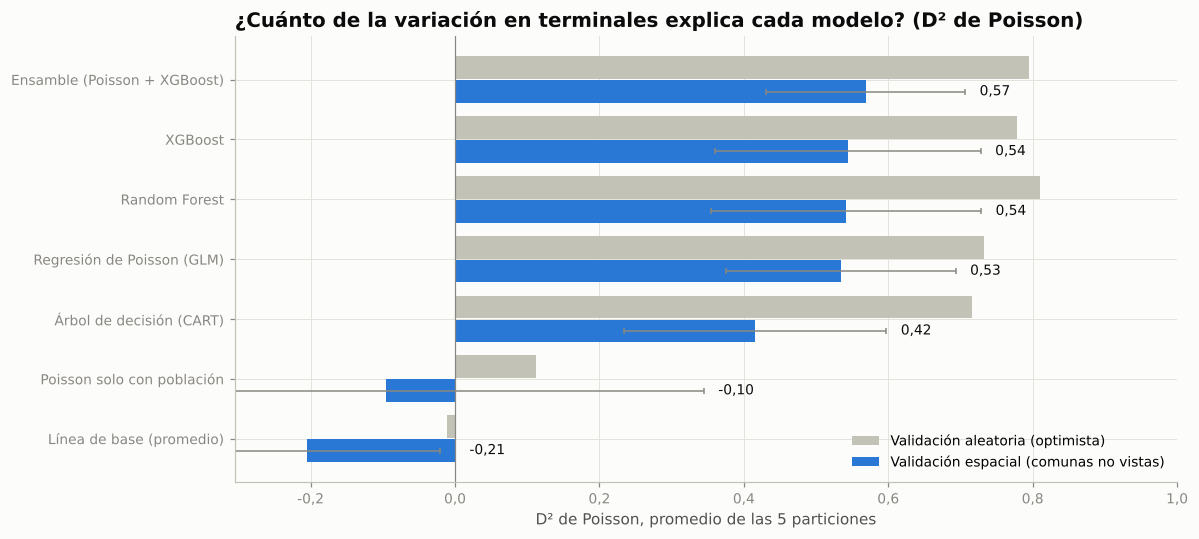

Modelo elegido: Ensamble (Poisson + XGBoost)


In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
yy = np.arange(len(orden))
ax.barh(yy - 0.2, ale.loc[orden, "D² Poisson (promedio por partición)"], height=0.38, color=e.EJE,
        label="Validación aleatoria (optimista)")
ax.barh(yy + 0.2, esp.loc[orden, "D² Poisson (promedio por partición)"], height=0.38, color=e.LINK,
        xerr=esp.loc[orden, "D² Poisson (desvío entre particiones)"], error_kw={"ecolor": e.TINTA_SUAVE, "linewidth": 1, "capsize": 2},
        label="Validación espacial (comunas no vistas)")
for i, (v, sd) in enumerate(zip(esp.loc[orden, "D² Poisson (promedio por partición)"], esp.loc[orden, "D² Poisson (desvío entre particiones)"])):
    ax.text(max(v + sd, 0) + 0.02, i + 0.2, e.num_es(v, 2), va="center", fontsize=9, color=e.TINTA)
ax.set_yticks(yy, orden); ax.invert_yaxis()
ax.set_xlim(min(-0.3, esp["D² Poisson (promedio por partición)"].min() - 0.1), 1)
ax.axvline(0, color=e.TINTA_SUAVE, linewidth=0.8)
ax.set(title="¿Cuánto de la variación en terminales explica cada modelo? (D² de Poisson)", xlabel="D² de Poisson, promedio de las 5 particiones")
ax.legend(loc="lower right"); e.ejes_es(ax, x=1); fig.tight_layout(); fig.savefig(FIG / "ml_comparacion.png"); plt.show()
print("Modelo elegido:", ganador)

In [6]:
hp = pd.read_csv(PROC / "hiperparametros.csv") if not RECALCULAR else pd.DataFrame(
    [{"modelo": k, "partición": i + 1, **p} for k, v in params.items() for i, p in enumerate(v)])
hp = hp.dropna(axis=1, how="all")
hp[hp["modelo"].isin(["Árbol de decisión (CART)", "Random Forest", "XGBoost", "Ensamble (Poisson + XGBoost)"])].set_index(["modelo", "partición"])

poissonregressor__alpha  max_depth  \
modelo                       partición                                       
Árbol de decisión (CART)     1                              NaN      6.000   
                             2                              NaN      4.000   
                             3                              NaN      6.000   
                             4                              NaN      5.000   
                             5                              NaN      3.000   
Random Forest                1                              NaN        NaN   
                             2                              NaN        NaN   
                             3                              NaN        NaN   
                             4                              NaN        NaN   
                             5                              NaN        NaN   
XGBoost                      1                              NaN      2.000   
                             2                              NaN      4.000   
                             3                              NaN      2.000   
                             4                              NaN      4.000   
                             5                              NaN      2.000   
Ensamble (Poisson + XGBoost) 1                              NaN        NaN   
                             2                              NaN        NaN   
                             3                              NaN        NaN   
                             4                              NaN        NaN   
                             5                              NaN        NaN   

                                        min_samples_leaf  max_features  \
modelo                       partición                                   
Árbol de decisión (CART)     1                    10.000           NaN   
                             2                    40.000           NaN   
                             3                    10.000           NaN   
                             4                    20.000           NaN   
                             5                    10.000           NaN   
Random Forest                1                     5.000         0.330   
                             2                     5.000         0.500   
                             3                     5.000         0.330   
                             4                     5.000         0.500   
                             5                     5.000         0.330   
XGBoost                      1                       NaN           NaN   
                             2                       NaN           NaN   
                             3                       NaN           NaN   
                             4                       NaN           NaN   
                             5                       NaN           NaN   
Ensamble (Poisson + XGBoost) 1                       NaN           NaN   
                             2                       NaN           NaN   
                             3                       NaN           NaN   
                             4                       NaN           NaN   
                             5                       NaN           NaN   

                                        min_child_weight  reg_lambda  \
modelo                       partición                                 
Árbol de decisión (CART)     1                       NaN         NaN   
                             2                       NaN         NaN   
                             3                       NaN         NaN   
                             4                       NaN         NaN   
                             5                       NaN         NaN   
Random Forest                1                       NaN         NaN   
                             2                       NaN         NaN   
                             3                


**Lectura: por qué elegimos este modelo y no otro.**

- Con la validación **aleatoria** el mejor es Random Forest (D² = 0,81): los modelos de árboles parecen
  imbatibles. Con la validación **espacial** el ranking cambia: Random Forest baja a 0,54. Los árboles aprenden la
  geografía de cada zona y, en una comuna que no vieron, esa memoria no les sirve (autocorrelación espacial). Si hubiéramos
  validado al azar, habríamos elegido mal.
- Gana el **Ensamble (Poisson + XGBoost)**: D² = 0,57 ± 0,14 entre grupos de comunas (el más alto y
  el más estable) y el menor error típico: erra en promedio **4,2 terminales por zona**, contra
  4,5 de la regresión de Poisson sola y 4,3 de XGBoost solo. Combina lo que cada parte hace
  bien: la regresión de Poisson extrapola mejor al microcentro, que tiene valores que los árboles no vieron, y XGBoost capta
  relaciones no lineales e interacciones entre variables.
- La regla simple "más vecinos, más cajeros" (Poisson solo con población) es **peor que predecir el promedio**
  (D² = -0,10): los cajeros siguen al comercio, no a los vecinos.
- XGBoost eligió árboles poco profundos (profundidad 2 a 4) en las 5 particiones: con
  2.740 zonas, los modelos simples generalizan mejor que los complejos.

## 3. Sobreajuste (clase 6) y error OOB (clase 8)

**Sobreajuste.** Un árbol más profundo siempre se ajusta mejor a los datos con los que entrena, pero a partir de cierta
profundidad empieza a memorizar ruido y predice peor en zonas nuevas. Lo medimos entrenando árboles de 1 a 15 niveles.

**OOB (out-of-bag).** En un Random Forest cada árbol se entrena con una muestra bootstrap y deja afuera, en promedio, un
tercio de las filas: con ellas se calcula un error "gratis". Comparamos ese OOB con el error en comunas no vistas.

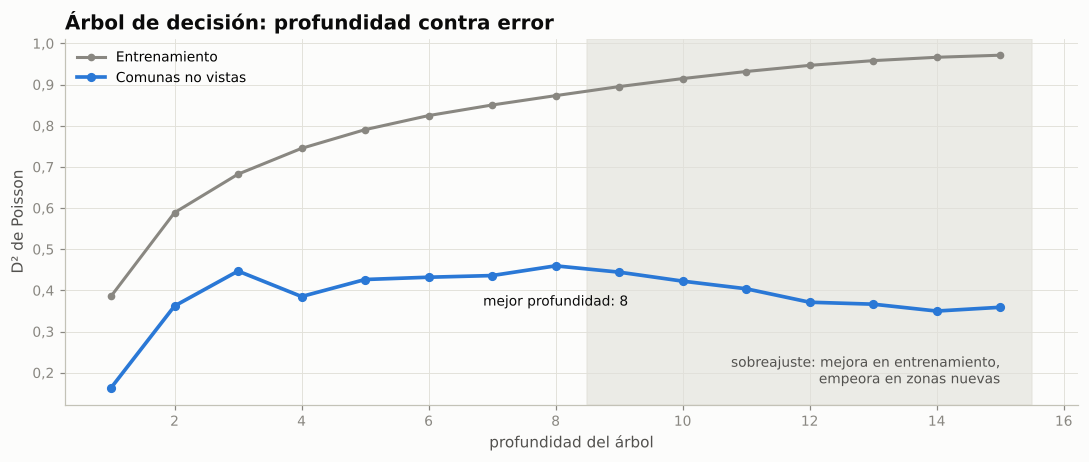

In [7]:
curva = ml.curva_profundidad(X, y, grupos) if RECALCULAR else pd.read_csv(PROC / "curva_profundidad.csv")
mejor = curva.loc[curva["validación espacial"].idxmax()]
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(curva["profundidad"], curva["entrenamiento"], color=e.TINTA_SUAVE, linewidth=2, marker="o", markersize=4, label="Entrenamiento")
ax.plot(curva["profundidad"], curva["validación espacial"], color=e.LINK, linewidth=2.4, marker="o", markersize=5, label="Comunas no vistas")
ax.axvspan(mejor["profundidad"] + 0.5, curva["profundidad"].max() + 0.5, color=e.GRILLA, alpha=0.6, zorder=0)
ax.annotate(f"mejor profundidad: {int(mejor['profundidad'])}", (mejor["profundidad"], mejor["validación espacial"]),
            xytext=(0, -26), textcoords="offset points", ha="center", fontsize=9, color=e.TINTA)
ax.text(curva["profundidad"].max(), curva["validación espacial"].min(), "sobreajuste: mejora en entrenamiento,\nempeora en zonas nuevas",
        ha="right", va="bottom", fontsize=9, color=e.TINTA_2)
ax.set(title="Árbol de decisión: profundidad contra error", xlabel="profundidad del árbol", ylabel="D² de Poisson")
ax.legend(loc="upper left"); e.ejes_es(ax, y=1); fig.tight_layout(); fig.savefig(FIG / "ml_curva_arbol.png"); plt.show()

In [8]:
if RECALCULAR:
    Xc, yc = ml.preparar_clasificacion(tabla, X, mascara)
    oob = ml.oob_vs_validacion(X, y, grupos, Xc, yc, ml.params_mas_frecuentes(params["Random Forest"]),
                               ml.params_mas_frecuentes(pd.read_csv(PROC / "hiperparametros_clasificacion.csv")
                                                        .query("modelo == 'Random Forest'")[["min_samples_leaf", "max_features"]]
                                                        .astype({"min_samples_leaf": int}).to_dict("records")))
else:
    oob = pd.read_csv(PROC / "oob_vs_validacion.csv")
oob

,modelo,métrica,OOB,comunas no vistas
0,Random Forest (regresión),R²,0.804,0.295
1,Random Forest (clasificación),AUC,0.852,0.838



**Lectura.** El árbol mejora siempre en entrenamiento (D² = 0,97 con 15 niveles), pero
en comunas no vistas el mejor resultado está en **8 niveles** (D² = 0,46) y después
empeora hasta 0,36: memoriza ruido. Es el sobreajuste de la clase 6, y es la razón por la que el
Random Forest y el boosting combinan muchos árboles en lugar de uno solo profundo.

El **OOB** del Random Forest da R² = 0,80, pero en comunas no vistas el R² es
0,29. El OOB deja afuera filas al azar, que tienen vecinas parecidas
adentro de la muestra, así que con datos espaciales es optimista: es la misma trampa que la validación aleatoria. En
clasificación la diferencia es chica (AUC 0,85 OOB contra
0,84), porque si una zona tiene o no cajero depende sobre todo de lo
que hay en el propio hexágono.

## 4. Qué aprendió el modelo (diagnóstico)

Tres miradas que se complementan:

- **Valores SHAP** del modelo elegido: para cada zona, cuánto empuja cada variable la predicción hacia arriba o hacia abajo
  respecto de una zona típica. El promedio de su valor absoluto mide la importancia de la variable. XGBoost los calcula de
  forma exacta (TreeSHAP); en la parte de Poisson es coeficiente × valor.
- **Importancia de Gini** (reducción de impureza) del Random Forest, la que vimos en la clase 8.
- **Coeficientes de la regresión de Poisson:** cuánto se multiplica lo esperado al subir un desvío cada variable.

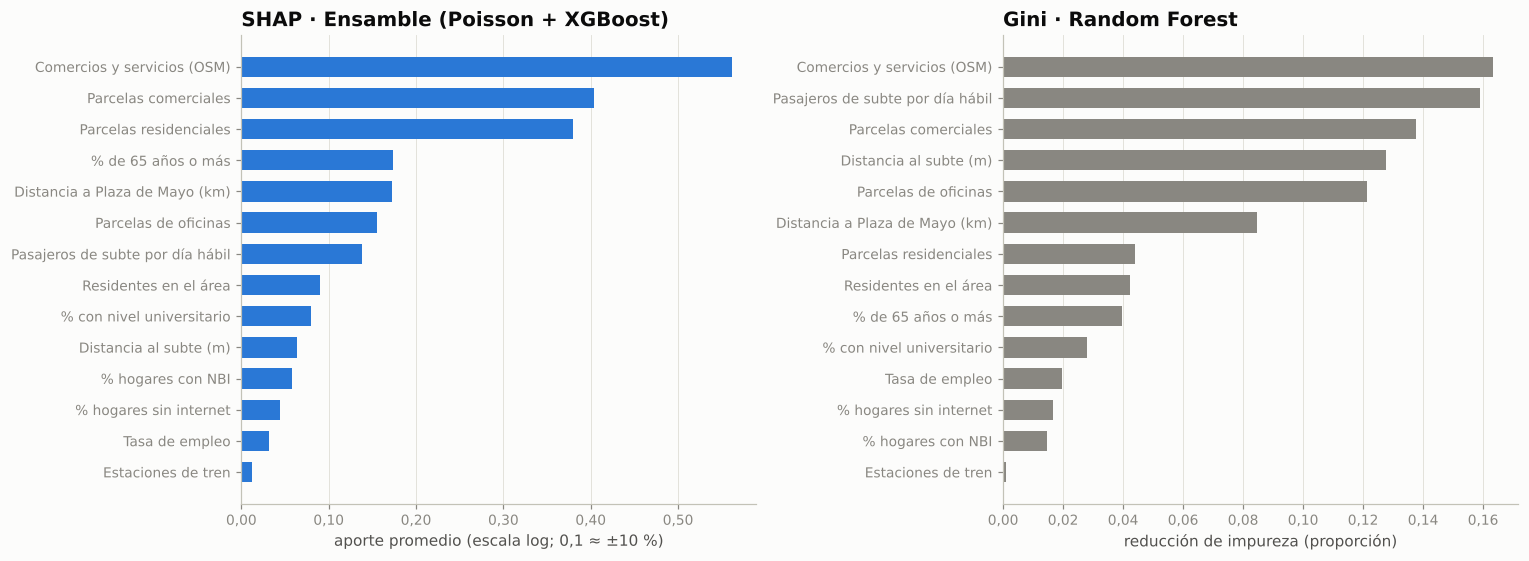

In [9]:
imp_shap = pd.read_csv(PROC / "importancia_variables.csv").sort_values("importancia")
imp_gini = pd.read_csv(PROC / "importancia_gini.csv").sort_values("importancia")
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
ax[0].barh(imp_shap["nombre"], imp_shap["importancia"], color=e.LINK, height=0.65)
ax[0].set(title=f"SHAP · {ganador}", xlabel="aporte promedio (escala log; 0,1 ≈ ±10 %)")
ax[1].barh(imp_gini["nombre"], imp_gini["importancia"], color=e.TINTA_SUAVE, height=0.65)
ax[1].set(title="Gini · Random Forest", xlabel="reducción de impureza (proporción)")
for a in ax:
    a.grid(axis="y", visible=False); e.ejes_es(a, x=2)
fig.tight_layout(); fig.savefig(FIG / "ml_importancia.png"); plt.show()

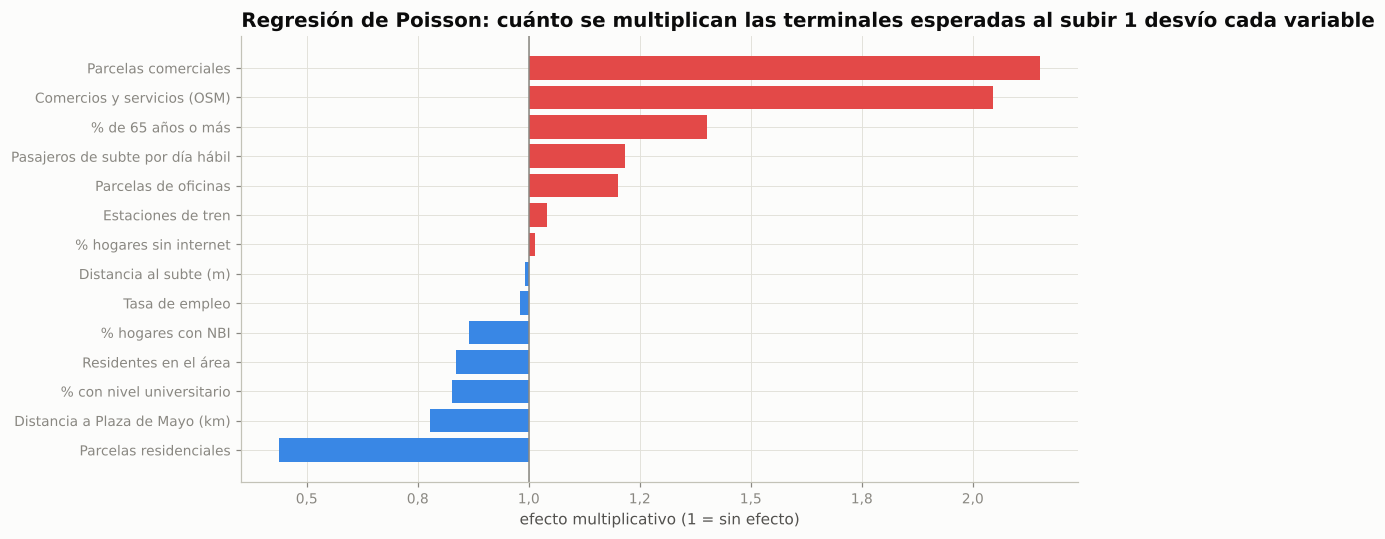

,nombre,coeficiente,efecto
0,Parcelas residenciales,-0.825,0.438
1,Distancia a Plaza de Mayo (km),-0.252,0.777
2,% con nivel universitario,-0.191,0.826
3,Residentes en el área,-0.179,0.836
4,% hogares con NBI,-0.143,0.866
5,Tasa de empleo,-0.019,0.981
6,Distancia al subte (m),-0.009,0.991
7,% hogares sin internet,0.014,1.014
8,Estaciones de tren,0.040,1.041
9,Parcelas de oficinas,0.184,1.201


In [10]:
coef = pd.read_csv(PROC / "coeficientes_glm.csv")
fig, ax = plt.subplots(figsize=(10, 5))
colores = [e.DIVERGENTE[-2] if c > 0 else e.DIVERGENTE[1] for c in coef["coeficiente"]]
ax.barh(coef["nombre"], coef["efecto"] - 1, left=1, color=colores)
ax.axvline(1, color=e.TINTA_SUAVE, linewidth=1)
ax.set(title="Regresión de Poisson: cuánto se multiplican las terminales esperadas al subir 1 desvío cada variable",
       xlabel="efecto multiplicativo (1 = sin efecto)")
e.ejes_es(ax, x=1); fig.tight_layout(); fig.savefig(FIG / "modelo_coeficientes.png"); plt.show()
coef[["nombre", "coeficiente", "efecto"]].round(3)


**Lectura.** Las tres miradas coinciden en lo principal: **el comercio y el tipo de tejido urbano pesan más que la cantidad
de vecinos**. Según SHAP, lo que más mueve la predicción es: comercios y servicios (osm), parcelas comerciales, parcelas residenciales. Según Gini del Random Forest: comercios y servicios (osm), pasajeros de subte por día hábil, parcelas comerciales (el
Random Forest le da más peso al subte porque, al no usar escala logarítmica, los cortes en pasajeros separan muy bien el
centro del resto).

En la regresión de Poisson, con lo demás fijo, subir un desvío las **parcelas comerciales** multiplica lo esperado por
2,15 y los **comercios** por 2,05; el **% de 65 años o más** por 1,40, coherente con un uso
más intensivo del efectivo en la población mayor; los **pasajeros de subte** por 1,22. En cambio, las **parcelas
residenciales** lo multiplican por 0,44 (barrios de casas bajas) y el **% de hogares con NBI** por 0,87: a
igual demanda, las zonas vulnerables tienen menos cajeros. Algunas variables están correlacionadas entre sí (residentes y
parcelas residenciales, por ejemplo), así que conviene leerlas en conjunto.

## 5. Cuántos cajeros le corresponden a cada barrio

Con el modelo elegido predecimos, para cada zona, cuántas terminales le corresponden según su demanda. Usamos las
predicciones **fuera de muestra**: cada zona la predice un modelo que no vio su comuna, así no se "explica" con sus propios
cajeros.

- **Brecha** = terminales que le corresponden − terminales que tiene.
- **Brecha Link** = lo que Link tendría con su participación en la ciudad − lo que tiene. Positivo = faltan terminales Link.

Para sumar por barrio, la predicción de cada área de influencia se reparte entre sus 7 hexágonos (si no, cada terminal se
contaría siete veces).

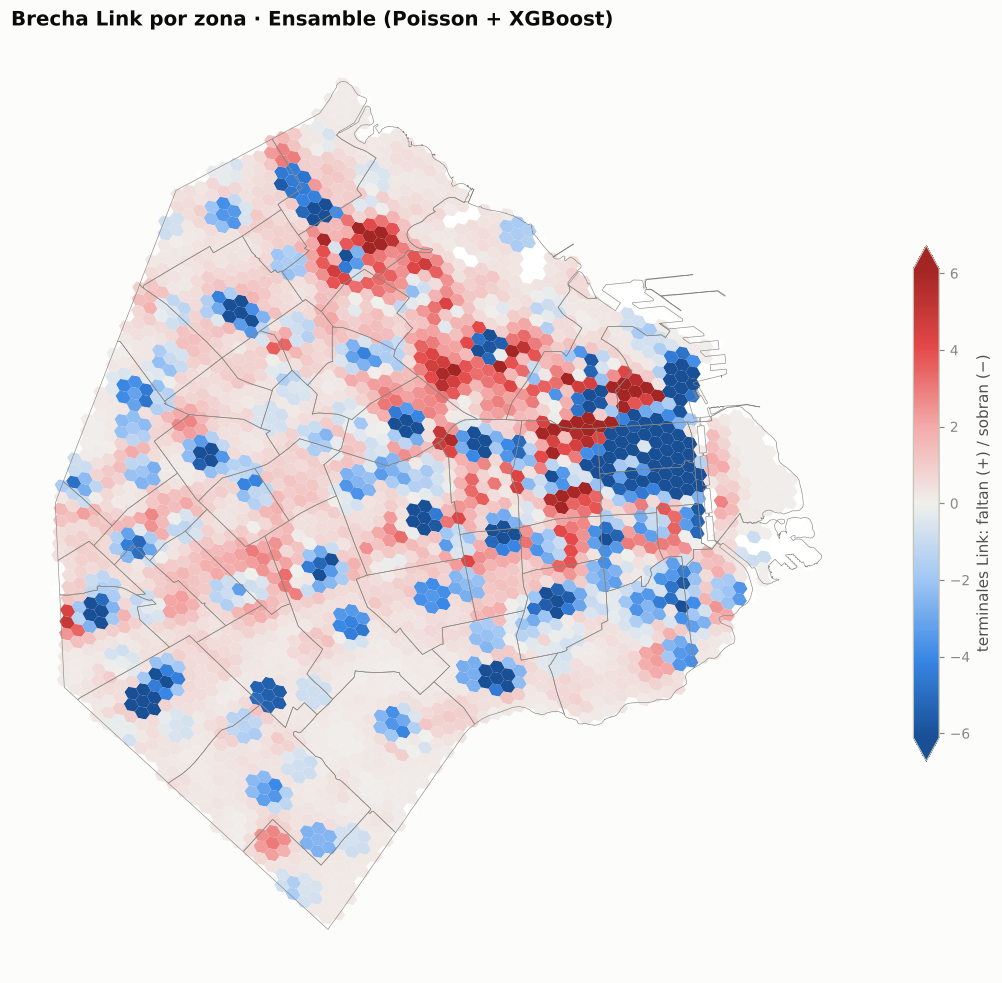

Participación de Link en las terminales de la ciudad: 34,5 %


In [11]:
g = gpd.GeoDataFrame(res, geometry=[f.poligono_hex(h) for h in res["h3"]], crs="EPSG:4326")
lim = np.nanquantile(np.abs(g["brecha_link"]), 0.95)
fig, ax = plt.subplots(figsize=(10, 9))
g.plot(column="brecha_link", cmap=e.cmap_divergente(), vmin=-lim, vmax=lim, ax=ax, linewidth=0, missing_kwds={"color": "#ffffff"},
       legend=True, legend_kwds={"label": "terminales Link: faltan (+) / sobran (−)", "shrink": 0.55})
barrios.boundary.plot(ax=ax, color=e.TINTA_SUAVE, linewidth=0.4)
ax.set_axis_off(); ax.set_title(f"Brecha Link por zona · {ganador}")
fig.tight_layout(); fig.savefig(FIG / "mapa_brecha_link.png"); plt.show()
print(f"Participación de Link en las terminales de la ciudad: {e.num_es(100 * res['term_link'].sum() / res['term_total'].sum(), 1)} %")

In [12]:
bp = pd.read_csv(PROC / "barrios_prediccion.csv", index_col="barrio")
vista = bp[["residentes", "comercios", "pasajeros_subte", "tiene_total", "corresponden_total", "tiene_link",
            "corresponden_link", "diferencia_link"]].round(1)
vista.head(12)

,residentes,comercios,pasajeros_subte,tiene_total,corresponden_total,tiene_link,corresponden_link,diferencia_link
barrio,,,,,,,,
Palermo,"242,274.800","3,415.000","40,856.300",184.000,239.200,47.000,82.500,35.500
Belgrano,"145,100.200","2,787.000","19,765.100",123.000,150.300,30.000,51.900,21.900
Recoleta,"160,736.300","2,306.000","39,473.900",205.000,190.000,57.000,65.600,8.600
Colegiales,"59,425.600",661.000,"8,100.500",38.000,40.200,7.000,13.800,6.800
San Cristóbal,"51,471.600",308.000,"15,901.100",21.000,35.100,6.000,12.100,6.100
Floresta,"36,712.800",268.000,0.000,11.000,24.200,3.000,8.400,5.400
Villa General Mitre,"35,420.600",244.000,0.000,6.000,13.500,0.000,4.600,4.600
Vélez Sarsfield,"35,991.600",294.000,0.000,7.000,19.900,3.000,6.900,3.900
Puerto Madero,"9,389.800",137.000,0.000,38.000,22.700,5.000,7.800,2.800


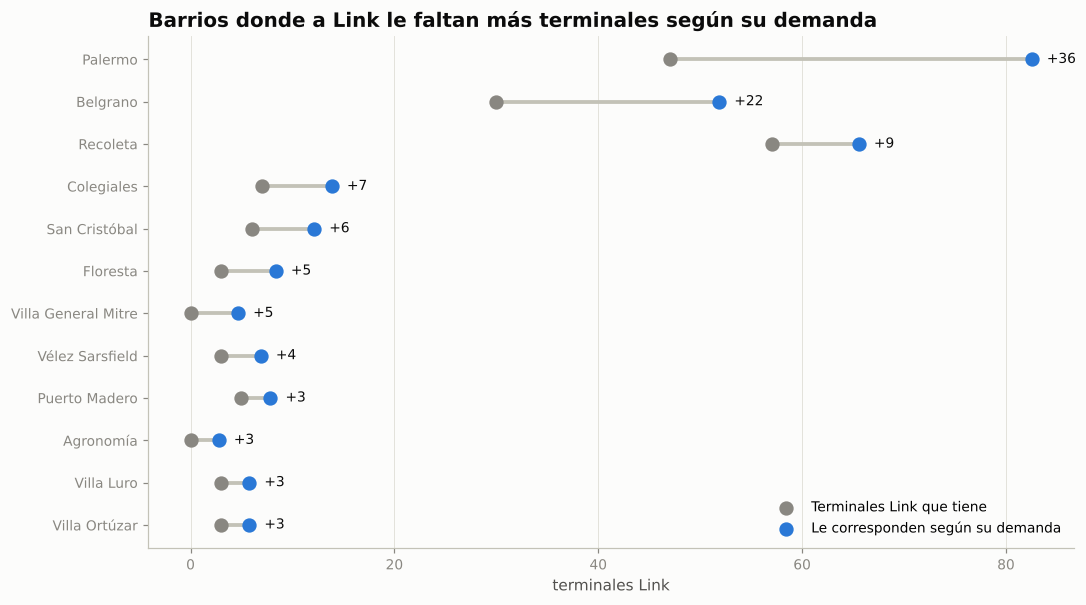

,tiene_link,corresponden_link,diferencia_link
barrio,,,
Mataderos,20.000,8.600,-11.400
Parque Patricios,24.000,12.000,-12.000
Retiro,41.000,26.800,-14.200
Monserrat,51.000,22.100,-28.900
San Nicolás,180.000,36.400,-143.600


In [13]:
top = bp[bp["diferencia_link"] > 0].head(12)
fig, ax = plt.subplots(figsize=(10, 5.6))
gm.tiene_vs_corresponden(top, ax)
ax.set_title("Barrios donde a Link le faltan más terminales según su demanda")
fig.tight_layout(); fig.savefig(FIG / "ml_corresponden_barrios.png"); plt.show()
bp.tail(5)[["tiene_link", "corresponden_link", "diferencia_link"]].round(1)


**Lectura.** Donde a Link más terminales le faltan según la demanda: **Palermo** (le corresponden 83, tiene 47); **Belgrano** (le corresponden 52, tiene 30); **Recoleta** (le corresponden 66, tiene 57); **Colegiales** (le corresponden 14, tiene 7); **San Cristóbal** (le corresponden 12, tiene 6). En todos domina Banelco.

Hay barrios donde Link **no tiene ninguna terminal** y por su demanda le corresponderían: **Villa General Mitre** (5), **Agronomía** (3), **Versalles** (2).

En el otro extremo está el microcentro: **San Nicolás** (le corresponden 36, tiene 180); **Monserrat** (le corresponden 22, tiene 51); **Retiro** (le corresponden 27, tiene 41). Ahí están las casas centrales de los bancos públicos de la red, y
el modelo no ve bien a la gente que trabaja en el centro (mide residentes, comercios y pasajeros de subte, pero no los
oficinistas que llegan en colectivo o tren), así que lo leemos como **sobreoferta a revisar**, no como cajeros que sobran.

## 6. Por qué: la explicación de cada zona (SHAP)

El modelo elegido es aditivo en escala logarítmica, así que la predicción de cada zona se descompone **exactamente** en el
aporte de cada variable: se parte de una zona típica y cada variable la multiplica por un factor (×2 duplica, ×0,5 reduce a
la mitad). Elegimos tres zonas con reglas fijas:

- **la de mayor faltante:** donde a Link más terminales le corresponden y no tiene ninguna;
- **una que alcanza con un cajero:** una zona residencial sin ningún cajero a la que le corresponde uno de Link;
- **una con mucha gente y poco flujo:** la zona de más de 15 mil vecinos a la que menos cajeros le corresponden.

In [14]:
ap = pd.read_parquet(PROC / "aportes_hex.parquet").set_index("h3")
r = res[res["esperado_total_k1"].notna()].set_index("h3")
Xh = X.set_index(tabla.loc[mascara, "h3"])
est = pd.read_csv(PROC / "estaciones_subte.csv")

def cerca(h):
    d = np.hypot((est["lat"] - r.loc[h, "lat"]) * 111_000, (est["lon"] - r.loc[h, "lon"]) * 92_000)
    i = d.idxmin()
    return f"a {e.num_es(round(d[i], -2))} m de {est.loc[i, 'estacion']} (línea {est.loc[i, 'linea']})"

zona_alta = r[r["term_link_k1"] == 0]["esperado_link_k1"].idxmax()
uno = r[(r["term_total_k1"] == 0) & r["esperado_link_k1"].between(0.5, 1.5) & (r["tipo_zona"] == "Residencial denso")]
zona_uno = uno["poblacion_k1"].idxmax()
zona_baja = r[r["poblacion_k1"] >= 15_000]["esperado_total_k1"].idxmin()
zonas = {"alta": zona_alta, "uno": zona_uno, "baja": zona_baja}
for clave, h in zonas.items():
    z = r.loc[h]
    print(f"{clave}: {z['barrio']} ({cerca(h)}) · {e.num_es(z['poblacion_k1'])} vecinos, {e.num_es(z['actividad_osm_k1'])} comercios, "
          f"{e.num_es(z['pax_subte_habil_k1'])} pasajeros de subte · le corresponden {e.num_es(z['esperado_total_k1'], 1)} "
          f"terminales ({e.num_es(z['esperado_link_k1'], 1)} Link) · tiene {e.num_es(z['term_total_k1'])} ({e.num_es(z['term_link_k1'])} Link)")

alta: Belgrano (a 600 m de Juramento (línea D)) · 17.264 vecinos, 555 comercios, 0 pasajeros de subte · le corresponden 30,1 terminales (10,4 Link) · tiene 5 (0 Link)
uno: Villa Urquiza (a 500 m de Juan Manuel de Rosas (línea B)) · 17.535 vecinos, 120 comercios, 0 pasajeros de subte · le corresponden 4,1 terminales (1,4 Link) · tiene 0 (0 Link)
baja: Villa Soldati (a 2.000 m de Plaza de los Virreyes - Eva Perón (línea E)) · 15.888 vecinos, 11 comercios, 0 pasajeros de subte · le corresponden 0,5 terminales (0,2 Link) · tiene 0 (0 Link)


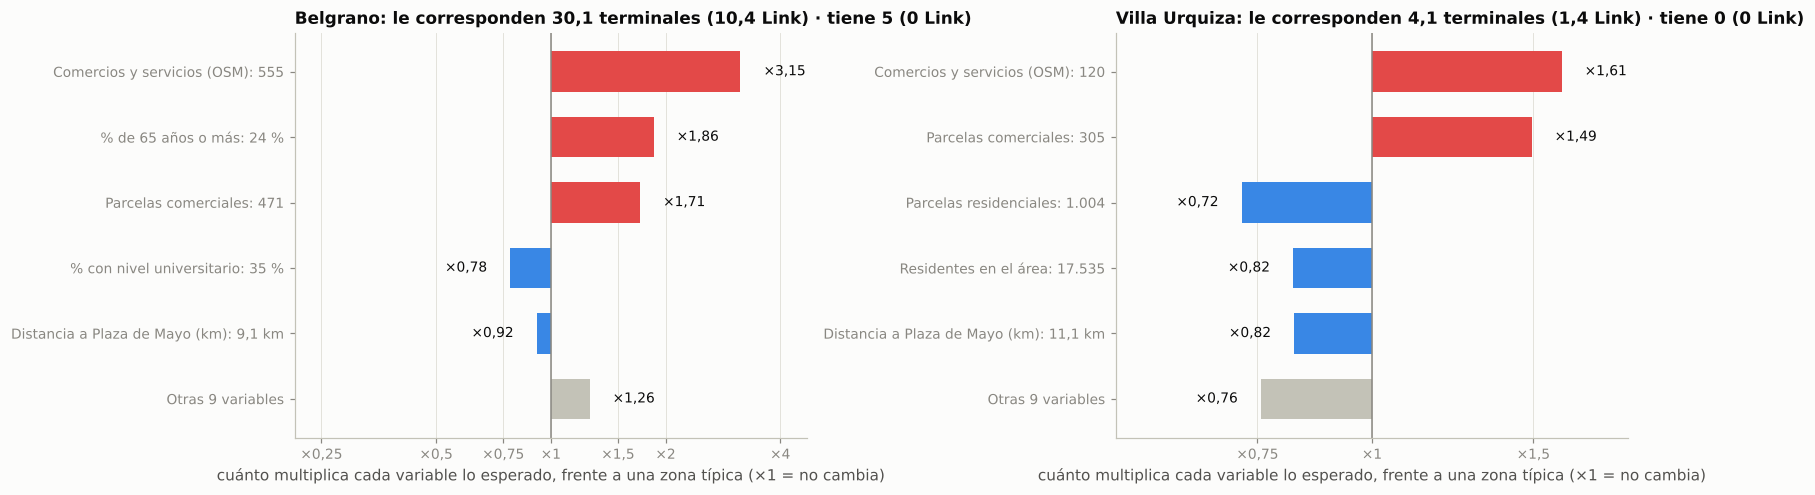

,variable,nombre,valor,aporte_log,factor
0,actividad_osm_k1,Comercios y servicios (OSM),11.000,-0.768,0.464
1,parcelas_oficinas_k1,Parcelas de oficinas,0.000,-0.601,0.548
2,pct_65_k1,% de 65 años o más,0.040,-0.524,0.592
3,parcelas_comercio_k1,Parcelas comerciales,24.000,-0.468,0.626
4,pct_nbi_k1,% hogares con NBI,0.145,-0.220,0.803
5,resto,Otras 9 variables,NaN,0.134,1.144


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, clave in zip(ax, ["alta", "uno"]):
    h = zonas[clave]; z = r.loc[h]
    tabla_ap = ml.explicar_zona(ap, Xh, h, n=5)
    gm.explicacion(tabla_ap, a, f"{z['barrio']}: le corresponden {e.num_es(z['esperado_total_k1'], 1)} terminales "
                                f"({e.num_es(z['esperado_link_k1'], 1)} Link) · tiene {e.num_es(z['term_total_k1'])} ({e.num_es(z['term_link_k1'])} Link)")
    a.set_xlabel("cuánto multiplica cada variable lo esperado, frente a una zona típica (×1 = no cambia)")
fig.tight_layout(); fig.savefig(FIG / "ml_explicacion_zonas.png"); plt.show()
ml.explicar_zona(ap, Xh, zonas["baja"], n=5).round(3)


**Lectura: tres zonas, tres decisiones.**

1. **Competir.** En Belgrano, a unos 600 m de la estación Juramento (línea D), hay 555 comercios en el área. Lo que más suma
   es comercios y servicios (osm) (×3,15) y % de 65 años o más (×1,86). Le corresponden **30 terminales (10 de Link)** y
   tiene 5, **ninguna de Link**.
2. **Alcanza con uno.** En una zona residencial de Villa Urquiza, a unos 500 m de la estación Juan Manuel de Rosas (línea B), viven 17.535 personas pero
   hay solo 120 comercios y no pasa el subte: el flujo de gente es bajo. Le corresponden
   4,1 terminales, o sea **un solo cajero Link**, y hoy no tiene ninguno de ninguna red.
3. **Mucha gente, poco flujo.** En Villa Soldati, a unos 2.000 m de la estación Plaza de los Virreyes - Eva Perón (línea E), viven 15.888 personas pero hay solo
   11 comercios: lo que más resta es comercios y servicios (osm) (×0,46) y parcelas de oficinas (×0,55). Le corresponden
   0,5 terminales. Por demanda comercial no le corresponde un cajero; si el objetivo es acercar el
   efectivo a quienes más lo usan, entra por la estrategia de **cubrir** (notebook 03), no por la de competir.

## 7. Clasificación: ¿a esta zona le corresponde al menos un cajero?

Misma idea, como clasificación: la zona (el hexágono) tiene o no al menos un cajero de cualquier red. Al mercado lo
tomamos como referencia: si zonas con demanda parecida tienen cajero, esta debería tener uno. Agregamos variables del propio
hexágono (residentes, comercios, pasajeros) a las del área.

- **Métricas:** AUC (probabilidad de que una zona con cajero tenga más puntaje que una sin cajero; 0,5 = azar) y PR-AUC.
- **Umbral:** el modelo marca tantas zonas como las que hoy tienen cajero (umbral de la tasa base). Con ese umbral precisión
  y recall coinciden.
- **Lectura de negocio de la matriz de confusión:** los **falsos positivos** (el modelo dice "debería tener" y no tiene) son
  **oportunidades**.

In [16]:
Xc, yc = ml.preparar_clasificacion(tabla, X, mascara)
if RECALCULAR:
    met_c, oof_c, params_c, _ = ml.comparar_clasificacion(Xc, yc, grupos)
    clasif_oof = pd.DataFrame({"h3": tabla.loc[mascara, "h3"].to_numpy(), "real": yc.to_numpy(), **oof_c})
else:
    met_c = pd.read_csv(PROC / "metricas_clasificacion.csv")
    clasif_oof = pd.read_parquet(PROC / "clasificacion_oof.parquet")
esp_c = met_c[met_c["validación"].str.startswith("espacial")].set_index("modelo")
ale_c = met_c[met_c["validación"] == "aleatoria"].set_index("modelo")
orden_c = esp_c.sort_values("AUC (promedio por partición)", ascending=False).index
clasificador = orden_c[0]
pd.DataFrame({"AUC espacial (promedio)": esp_c.loc[orden_c, "AUC (promedio por partición)"],
              "AUC espacial": esp_c.loc[orden_c, "AUC"], "PR-AUC espacial": esp_c.loc[orden_c, "PR-AUC"],
              "Precisión = Recall": esp_c.loc[orden_c, "Precisión"], "AUC aleatoria": ale_c.loc[orden_c, "AUC"]})

,AUC espacial (promedio),AUC espacial,PR-AUC espacial,Precisión = Recall,AUC aleatoria
modelo,,,,,
Random Forest,0.830,0.835,0.606,0.572,0.852
XGBoost,0.830,0.838,0.604,0.570,0.848
Regresión logística,0.827,0.836,0.624,0.594,0.842
Árbol de decisión,0.795,0.811,0.547,0.542,0.817


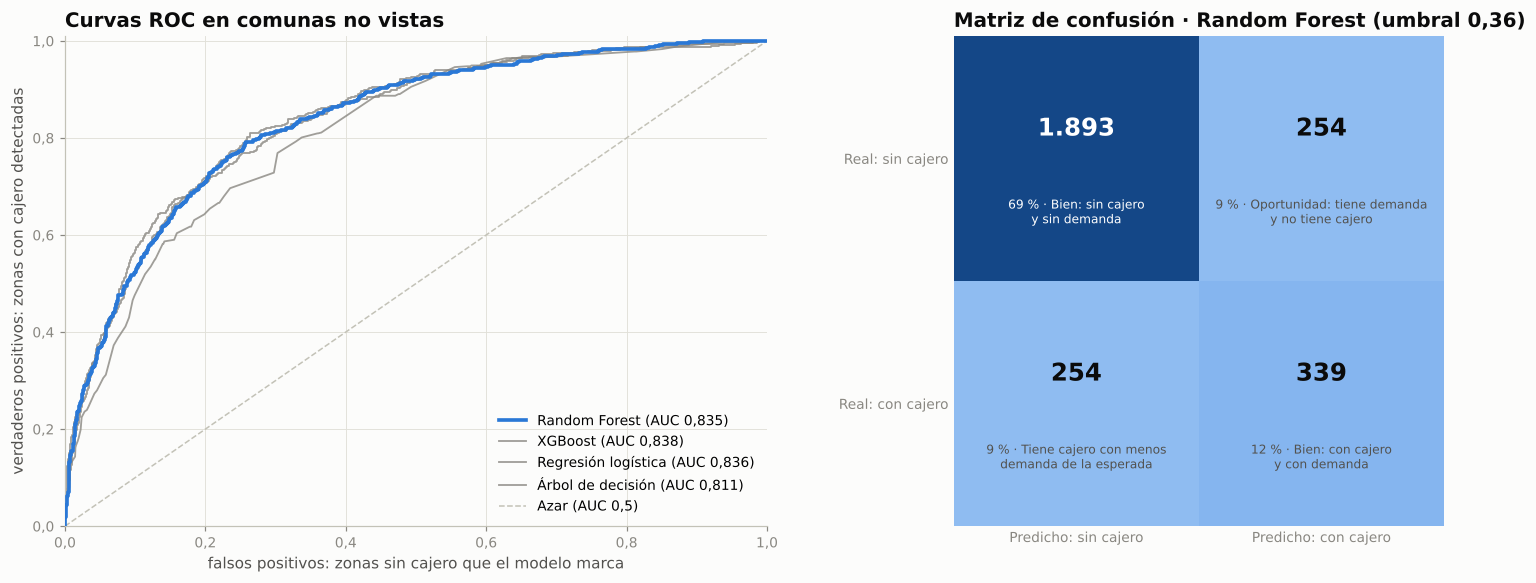

,Predicho: sin cajero,Predicho: con cajero
Real: sin cajero,1893,254
Real: con cajero,254,339


In [17]:
umbral = ml.umbral_tasa_base(clasif_oof["real"].to_numpy(), clasif_oof[clasificador].to_numpy())
cm = ml.matriz(clasif_oof["real"].to_numpy(), clasif_oof[clasificador].to_numpy(), umbral)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
gm.roc(clasif_oof, list(orden_c), clasificador, ax[0])
ax[0].set_title("Curvas ROC en comunas no vistas")
gm.matriz(cm, ax[1])
ax[1].set_title(f"Matriz de confusión · {clasificador} (umbral {e.num_es(umbral, 2)})")
fig.tight_layout(); fig.savefig(FIG / "ml_clasificacion.png"); plt.show()
cm

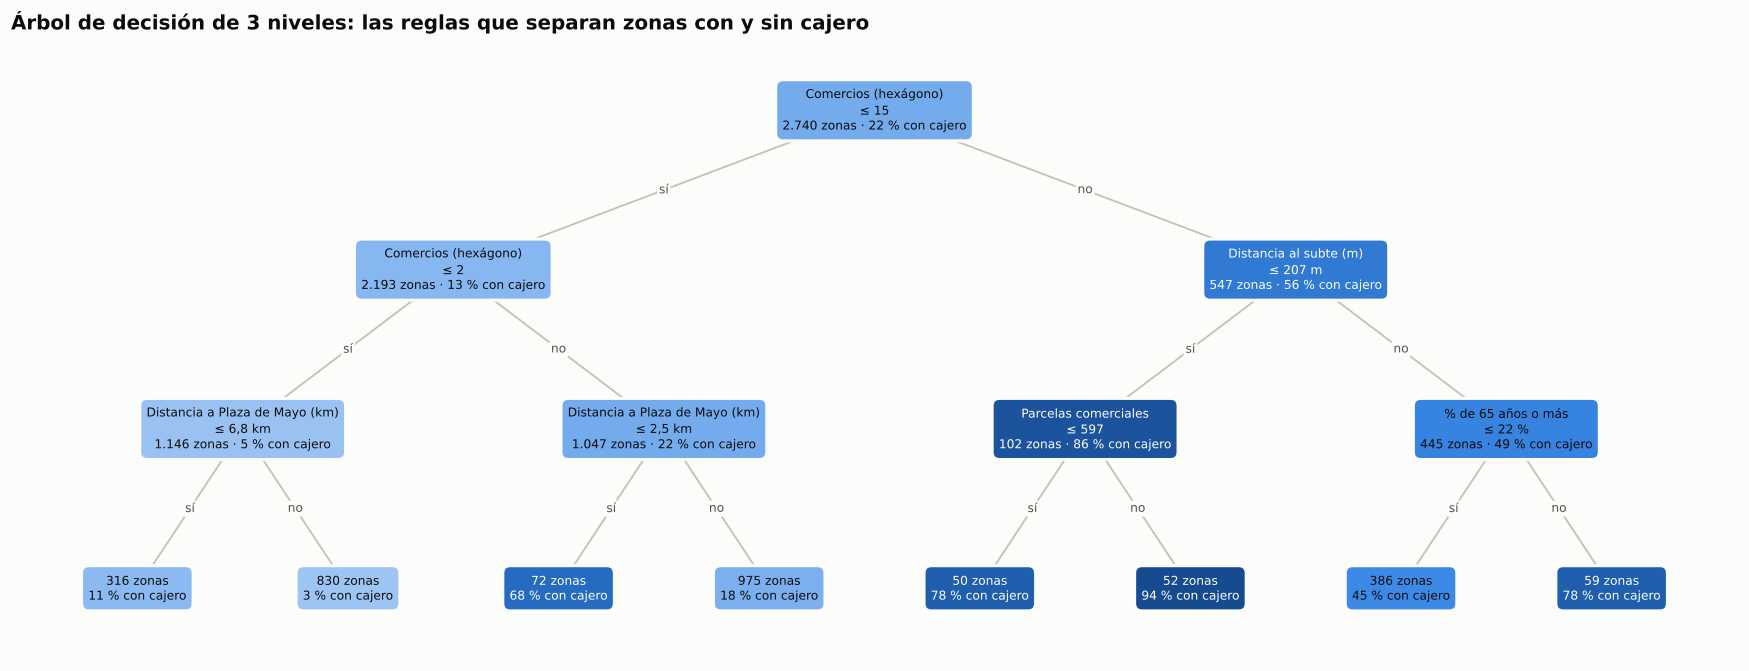

In [18]:
arbol = ml.arbol_explicativo(Xc, yc, profundidad=3)
fig, ax = plt.subplots(figsize=(16, 6.2))
gm.arbol(arbol, ml.NOMBRES, ax)
ax.set_title("Árbol de decisión de 3 niveles: las reglas que separan zonas con y sin cajero")
fig.tight_layout(); fig.savefig(FIG / "ml_arbol.png"); plt.show()

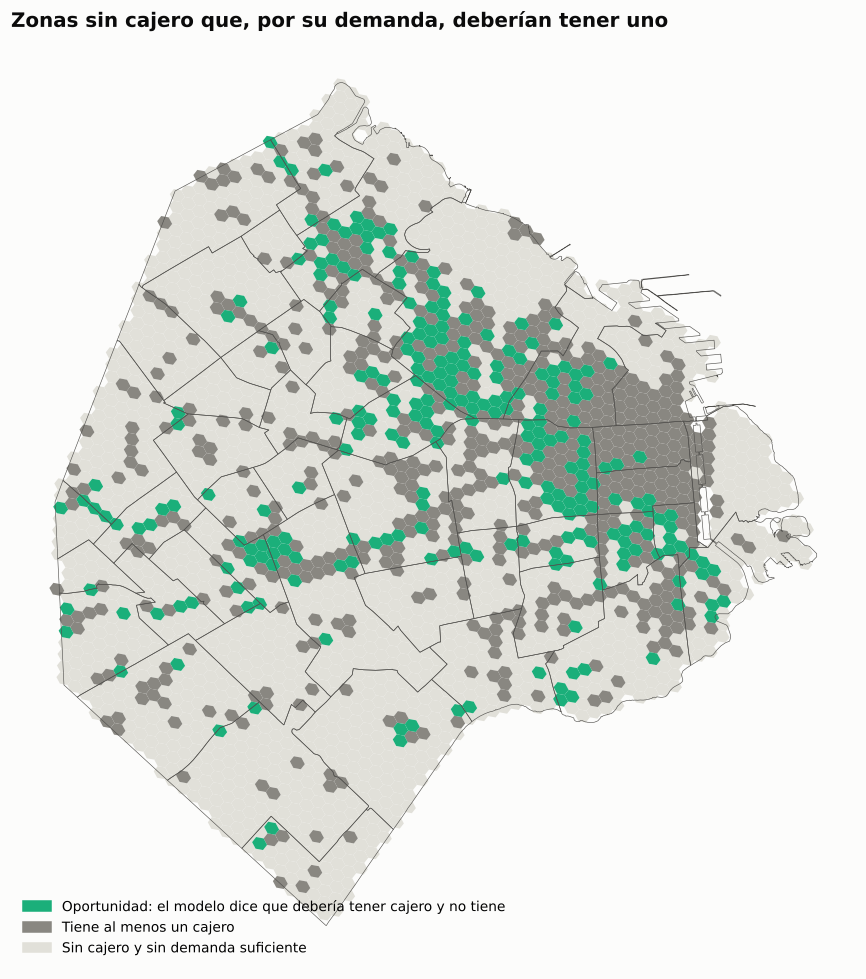

254 zonas sin ningún cajero que deberían tener uno · 480.545 vecinos


barrio
Palermo          50
Balvanera        26
Belgrano         17
Villa Crespo     17
Recoleta         14
Flores            9
Caballito         9
Constitución      8
Barracas          8
San Cristóbal     7
dtype: int64

In [19]:
rr = res.merge(clasif_oof[["h3", clasificador]].rename(columns={clasificador: "p"}), on="h3", how="left")
rr["clase"] = np.select([rr["term_total"] > 0, rr["p"] >= umbral], ["con cajero", "oportunidad"], "sin cajero, sin demanda suficiente")
gg = gpd.GeoDataFrame(rr, geometry=[f.poligono_hex(h) for h in rr["h3"]], crs="EPSG:4326")
fig, ax = plt.subplots(figsize=(10, 9))
gg[gg["clase"] == "sin cajero, sin demanda suficiente"].plot(ax=ax, color=e.GRILLA, linewidth=0)
gg[gg["clase"] == "con cajero"].plot(ax=ax, color=e.TINTA_SUAVE, linewidth=0)
gg[gg["clase"] == "oportunidad"].plot(ax=ax, color=e.SUGERIDO, linewidth=0)
barrios.boundary.plot(ax=ax, color=e.TINTA_2, linewidth=0.4)
ax.legend(handles=[Patch(color=e.SUGERIDO, label="Oportunidad: el modelo dice que debería tener cajero y no tiene"),
                   Patch(color=e.TINTA_SUAVE, label="Tiene al menos un cajero"),
                   Patch(color=e.GRILLA, label="Sin cajero y sin demanda suficiente")], loc="lower left")
ax.set_axis_off(); ax.set_title("Zonas sin cajero que, por su demanda, deberían tener uno")
fig.tight_layout(); fig.savefig(FIG / "ml_mapa_oportunidades.png"); plt.show()
op = rr[rr["clase"] == "oportunidad"]
print(f"{len(op)} zonas sin ningún cajero que deberían tener uno · {e.num_es(op['poblacion'].sum())} vecinos")
op.groupby("barrio").size().sort_values(ascending=False).head(10)


**Lectura.** Los clasificadores quedan muy cerca (AUC en comunas no vistas entre 0,81 y 0,84) y el
árbol solo queda último, como se espera. Por la regla fijada (mayor AUC promedio por grupo de comunas) elegimos
**Random Forest**: AUC = 0,84. Con el umbral de la tasa base acierta 6 de cada 10 zonas que marca.

La matriz de confusión, en negocio: 339 zonas con cajero bien detectadas, 1.893 sin cajero bien detectadas,
254 zonas con cajero y menos demanda de la esperada, y **254 oportunidades**: zonas sin ningún cajero de ninguna red
que, por su demanda, deberían tener uno. En ellas viven **480.545 personas** y se concentran en
Palermo, Balvanera, Belgrano, Villa Crespo.

El árbol de 3 niveles, que no usamos para predecir sino para leer las reglas, empieza preguntando por
**comercios (hexágono)**: es la variable que mejor separa zonas con y sin cajero, coherente con la importancia de la sección 4.

## 8. Validación hacia el futuro

El listado de cajeros es de ≈2017. En OpenStreetMap hay cajeros mapeados hasta 2026: los que están a más de 150 m de
cualquier cajero del listado son, muy probablemente, **instalados después**. Si los modelos, entrenados con la foto de 2017,
predicen algo real, esos cajeros nuevos tendrían que haber aparecido donde marcaban brecha o probabilidad alta.

In [20]:
val = pd.read_csv(PROC / "validacion_temporal.csv")
R = json.loads((PROC / "resumen.json").read_text(encoding="utf-8"))
print(f"Cajeros nuevos en OSM: {R['cajeros_nuevos_osm']} · cayeron en el percentil {e.num_es(100 * R['percentil_cajeros_nuevos'])} "
      f"de la brecha 2017 (p = {e.num_es(R['p_valor_cajeros_nuevos'], 3)}, 20.000 sorteos al azar)")
val.round(3)

Cajeros nuevos en OSM: 9 · cayeron en el percentil 67 de la brecha 2017 (p = 0,042, 20.000 sorteos al azar)


,puntaje,AUC,hexagonos_cerca_de_cajero_nuevo
0,Brecha total del modelo (2017),0.644,55
1,Demanda esperada del modelo,0.605,55
2,Solo residentes,0.509,55
3,Probabilidad de cajero (clasificador),0.577,55



**Lectura.** De los 206 cajeros de OpenStreetMap, 9 no tienen ningún cajero del listado 2017 a
menos de 150 m: muy probablemente son nuevos. Cayeron, en promedio, en el **percentil 67** de la
brecha calculada con datos de 2017 (al azar se esperaría el 50; p = 0,042). El AUC de la brecha es
0,64 y el de la probabilidad del clasificador, 0,58, contra 0,51 de mirar solo los residentes.

Es una **evidencia a favor, pero modesta**: son pocos cajeros y OpenStreetMap no está completo. La leemos así: el mercado
tendió a instalar cajeros donde los modelos marcaban faltante, y no al azar.

## 9. Conclusión


- **Machine learning predictivo:** comparamos 7 modelos de regresión y 4 de clasificación con validación cruzada espacial
  anidada. Ganan el **Ensamble (Poisson + XGBoost)** (D² = 0,57, MAE = 4,2 terminales por zona) y
  **Random Forest** (AUC = 0,84).
- **Diagnóstico:** los cajeros siguen al comercio y al flujo de gente, no a la cantidad de vecinos; las zonas vulnerables tienen
  menos cajeros que los que les corresponden por su demanda.
- **Resultado de negocio:** a Link le faltan terminales sobre todo en Palermo, Belgrano, Recoleta; hay barrios sin ningún Link a los
  que les corresponde alguno (Villa General Mitre, Agronomía, Versalles); y 254 zonas sin ningún cajero deberían tener uno.
- **Validación:** los cajeros instalados después de 2017 aparecieron donde los modelos marcaban faltante (p = 0,042).
- **Siguiente paso:** el notebook 03 convierte esto en una decisión: cuántos cajeros sumar y dónde, para llegar a más gente.